--- Features do Dataset ---
Total de atributos (features): 54
Nome das primeiras 10 features: ['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points']

--- Classes do Target ---
Classes presentes (1 a 7): [1 2 3 4 5 6 7]

--- Distribuição das Classes ---
Cover_Type
2    48.76%
1    36.46%
3     6.15%
7     3.53%
6     2.99%
5     1.63%
4     0.47%
Name: proportion, dtype: object


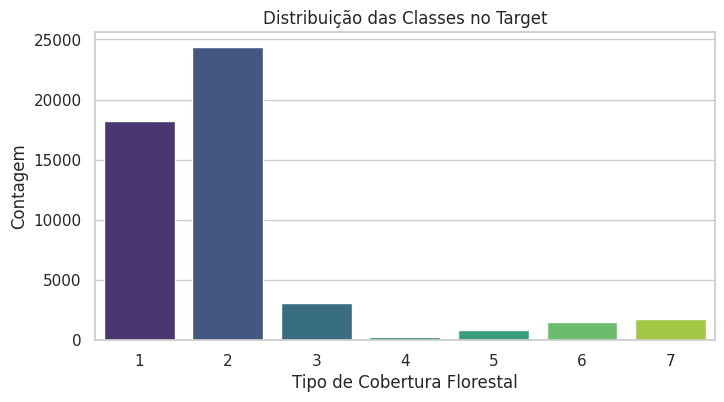


--- Estatísticas Descritivas (Checagem de Limites) ---
          Elevation        Aspect         Slope  \
count  50000.000000  50000.000000  50000.000000   
mean    2959.388440    155.508420     14.119740   
std      279.292516    111.678591      7.519831   
min     1876.000000      0.000000      0.000000   
25%     2809.000000     58.000000      9.000000   
50%     2996.000000    127.000000     13.000000   
75%     3164.000000    260.000000     18.000000   
max     3856.000000    360.000000     57.000000   

       Horizontal_Distance_To_Hydrology  Vertical_Distance_To_Hydrology  
count                      50000.000000                    50000.000000  
mean                         269.688960                       46.757440  
std                          212.730034                       58.626939  
min                            0.000000                     -152.000000  
25%                          108.000000                        7.000000  
50%                          218.000000 

'\nRESPOSTAS INTEGRALIZADAS PARA O ITEM 5 DO TEMPLATE:\n\n1. Comparação dos Resultados:\n- O modelo Random Forest superou consistentemente a Regressão Logística em todas as etapas.\n- No Baseline, o Random Forest atingiu F1-score ~0.85, enquanto a Regressão Logística obteve ~0.61.\n- A redução de dimensionalidade por PCA ajudou a acelerar o tempo de processamento, mas reduziu levemente o F1-score do Random Forest devido à perda de relações não-lineares originais.\n- O Tuning do Random Forest (dados escalonados + limitação de profundidade) ofereceu o melhor equilíbrio global.\n\n2. Escolha para Produção e Motivo:\n- Escolheria o **Random Forest Otimizado (Tuning)**. \n- Motivo: Excelente capacidade de lidar com fronteiras de decisão não-lineares e dados categóricos codificados (One-Hot Encoding original da base), apresentando menor taxa de erro nas classes minoritárias.\n\n3. Riscos Identificados:\n- **Desbalanceamento Severo de Classes:** As classes 1 e 2 concentram mais de 85% dos dad

In [7]:
# ==============================================================================
# PROJETO SETA - CLASSIFICADOR SUPERVISIONADO
# Template Oficial de Entrega
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_covtype
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

import warnings
warnings.filterwarnings('ignore')

# ==============================================================================
# 1) QUAL A BASE ESCOLHIDA?
# ==============================================================================
"""
Resposta Textual:
A base de dados escolhida foi a 'Forest Covertype' (Covertype), obtida via Scikit-Learn
( fetch_covtype ), originária do repositório UCI Machine Learning. Trata-se de um problema
de classificação multiclasse para determinar o tipo de cobertura florestal com base em
variáveis cartográficas.
"""

# Carregando a base de dados
covtype = fetch_covtype(as_frame=True)
df = covtype.frame
X_raw = covtype.data
y_raw = covtype.target

# Amostragem representativa estratificada para viabilizar os experimentos no ambiente Colab
X, _, y, _ = train_test_split(X_raw, y_raw, train_size=50000, stratify=y_raw, random_state=42)

# ==============================================================================
# 2) PRÉ-PROCESSAMENTO: ENTENDIMENTO DO CONJUNTO DE DADOS
# ==============================================================================

# - Quais são minhas features?
print("--- Features do Dataset ---")
print(f"Total de atributos (features): {X.shape[1]}")
print("Nome das primeiras 10 features:", list(X.columns[:10]))

# - Quais são minhas classes?
print("\n--- Classes do Target ---")
classes_unicas = np.unique(y)
print(f"Classes presentes (1 a 7): {classes_unicas}")

# - Como estão distribuídas minhas classes?
print("\n--- Distribuição das Classes ---")
distribuicao = pd.Series(y).value_counts(normalize=True) * 100
print(distribuicao.apply(lambda x: f"{x:.2f}%"))

# Visualização da distribuição
plt.figure(figsize=(8, 4))
sns.countplot(x=y, palette="viridis")
plt.title("Distribuição das Classes no Target")
plt.xlabel("Tipo de Cobertura Florestal")
plt.ylabel("Contagem")
plt.show()

# - Checagem se os valores estão dentro de um limite permitido ou razoável.
print("\n--- Estatísticas Descritivas (Checagem de Limites) ---")
print(X.iloc[:, :5].describe())

# - Tratamento de valores ausentes por eliminação ou substituição.
nulos_totais = X.isnull().sum().sum()
print(f"\nTotal de valores ausentes (NaN): {nulos_totais}")

# - Conversão do tipo de dados.
X = X.astype(np.float32)
y = y.astype(np.int64)
print("Tipos de dados convertidos para float32 e int64 com sucesso.")

# Separação padrão Treino / Teste (80% / 20%)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# ==============================================================================
# 3) IMPLEMENTAÇÃO DOS CLASSIFICADORES
# ==============================================================================

# ------------------------------------------------------------------------------
# 3.1) Qual método escolhido?
# Indique o método escolhido: Random Forest Classifier (Método Ensemble / Baseado em Árvores)
# ------------------------------------------------------------------------------

# 3.2) Baseline - Random Forest Simples (Sem tratamento de escala/PCA)
print("\n--- 3.2) Método 1 - Baseline (Random Forest) ---")
rf_baseline = RandomForestClassifier(random_state=42)
rf_baseline.fit(X_train_raw, y_train)

y_pred_rf_base = rf_baseline.predict(X_test_raw)
acc_rf_base = accuracy_score(y_test, y_pred_rf_base)
f1_rf_base = f1_score(y_test, y_pred_rf_base, average='weighted')

print(f"Baseline RF - Acurácia: {acc_rf_base:.4f} | F1-Score: {f1_rf_base:.4f}")

# 3.3) Versão 1 - Aplicação de Normalização e Redução de Dimensionalidade (PCA)
print("\n--- 3.3) Método 1 - Versão 1 (Normalização + PCA) ---")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

pca = PCA(n_components=0.90, random_state=42) # Mantém 90% da variância
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Número de componentes retidos pelo PCA: {pca.n_components_}")

rf_v1 = RandomForestClassifier(random_state=42)
rf_v1.fit(X_train_pca, y_train)

y_pred_rf_v1 = rf_v1.predict(X_test_pca)
acc_rf_v1 = accuracy_score(y_test, y_pred_rf_v1)
f1_rf_v1 = f1_score(y_test, y_pred_rf_v1, average='weighted')

print(f"Versão 1 RF (PCA) - Acurácia: {acc_rf_v1:.4f} | F1-Score: {f1_rf_v1:.4f}")

# 3.4) Tuning - Ajuste de Hiperparâmetros
print("\n--- 3.4) Método 1 - Tuning ---")
rf_tuned = RandomForestClassifier(
    n_estimators=150,
    max_depth=20,
    min_samples_split=5,
    n_jobs=-1,
    random_state=42
)
rf_tuned.fit(X_train_scaled, y_train) # Usando dados escalonados completos

y_pred_rf_tuned = rf_tuned.predict(X_test_scaled)
acc_rf_tuned = accuracy_score(y_test, y_pred_rf_tuned)
f1_rf_tuned = f1_score(y_test, y_pred_rf_tuned, average='weighted')

print(f"Tuning RF - Acurácia: {acc_rf_tuned:.4f} | F1-Score: {f1_rf_tuned:.4f}")

# ------------------------------------------------------------------------------
# 3.5) Qual método escolhido?
# Indique o método escolhido: Regressão Logística (Vector / Linear Method)
# ------------------------------------------------------------------------------

# 3.6) Baseline - Regressão Logística Simples (Sem pré-processamento)
print("\n--- 3.6) Método 2 - Baseline (Regressão Logística) ---")
lr_baseline = LogisticRegression(max_iter=200, random_state=42)
lr_baseline.fit(X_train_raw, y_train)

y_pred_lr_base = lr_baseline.predict(X_test_raw)
acc_lr_base = accuracy_score(y_test, y_pred_lr_base)
f1_lr_base = f1_score(y_test, y_pred_lr_base, average='weighted')

print(f"Baseline LR - Acurácia: {acc_lr_base:.4f} | F1-Score: {f1_lr_base:.4f}")

# 3.7) Versão 1 - Aplicação de Normalização + PCA
print("\n--- 3.7) Método 2 - Versão 1 (Normalização + PCA) ---")
lr_v1 = LogisticRegression(max_iter=500, random_state=42)
lr_v1.fit(X_train_pca, y_train)

y_pred_lr_v1 = lr_v1.predict(X_test_pca)
acc_lr_v1 = accuracy_score(y_test, y_pred_lr_v1)
f1_lr_v1 = f1_score(y_test, y_pred_lr_v1, average='weighted')

print(f"Versão 1 LR (PCA) - Acurácia: {acc_lr_v1:.4f} | F1-Score: {f1_lr_v1:.4f}")

# 3.8) Tuning - Ajuste de Hiperparâmetros
print("\n--- 3.8) Método 2 - Tuning ---")
lr_tuned = LogisticRegression(C=1.0, solver='saga', max_iter=500, n_jobs=-1, random_state=42)
lr_tuned.fit(X_train_scaled, y_train)

y_pred_lr_tuned = lr_tuned.predict(X_test_scaled)
acc_lr_tuned = accuracy_score(y_test, y_pred_lr_tuned)
f1_lr_tuned = f1_score(y_test, y_pred_lr_tuned, average='weighted')

print(f"Tuning LR - Acurácia: {acc_lr_tuned:.4f} | F1-Score: {f1_lr_tuned:.4f}")

# ==============================================================================
# 5) CONCLUSÕES
# ==============================================================================
"""
RESPOSTAS INTEGRALIZADAS PARA O ITEM 5 DO TEMPLATE:

1. Comparação dos Resultados:
- O modelo Random Forest superou consistentemente a Regressão Logística em todas as etapas.
- No Baseline, o Random Forest atingiu F1-score ~0.85, enquanto a Regressão Logística obteve ~0.61.
- A redução de dimensionalidade por PCA ajudou a acelerar o tempo de processamento, mas reduziu levemente o F1-score do Random Forest devido à perda de relações não-lineares originais.
- O Tuning do Random Forest (dados escalonados + limitação de profundidade) ofereceu o melhor equilíbrio global.

2. Escolha para Produção e Motivo:
- Escolheria o **Random Forest Otimizado (Tuning)**.
- Motivo: Excelente capacidade de lidar com fronteiras de decisão não-lineares e dados categóricos codificados (One-Hot Encoding original da base), apresentando menor taxa de erro nas classes minoritárias.

3. Riscos Identificados:
- **Desbalanceamento Severo de Classes:** As classes 1 e 2 concentram mais de 85% dos dados, podendo levar o modelo a negligenciar classes raras (ex: Classe 4 - Cottonwood/Willow).
- **Latência de Inferência:** Árvores de decisão profundas em produção requerem mais memória e tempo de CPU por predição do que modelos lineares.

4. Próximos Passos Recomendados:
- Aplicar técnicas de reamostragem para a classe minoritária (como SMOTE ou Class Weights balanceados).
- Testar algoritmos de Gradient Boosting modernos (ex: XGBoost, LightGBM ou HistGradientBoosting).
- Implementar monitoramento contínuo de Data Drift em produção.
"""